In [1]:
#Gabe's presets
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
from cycler import cycler

# ==============================================================================
# UNIFORM PLOT STYLE CONFIGURATION
# ==============================================================================

# Font & Typography
FONT_FAMILY = 'Segoe UI'
FONT_SIZE = 18
AXIS_TITLE_FONT_SIZE = 22
LEGEND_FONT_SIZE = 16
TICK_LABEL_SIZE = 16

# Elements & Dimensions
LINE_WIDTH = 3
MARKER_SIZE = 4
FIGURE_SIZE = (9, 7)
AXIS_LINE_COLOR = 'darkgrey'

# Legend Defaults
LEGEND_LOCATION = 'lower center'
LEGEND_BBOX = (0.5, 1.05)

# Date Formatting
DATE_FORMAT = DateFormatter('%b %d, %H:%M')

# Color Palettes (Tol's Muted & Custom Sim)
COLOR_PALETTE_MEASURE = ['#CC6677', '#332288', '#882255', '#88CCEE', '#AA4499', '#DDCC77']
COLOR_PALETTE_SIM = ['#44AA99', '#999933', '#AA4499', '#DDCC77']


def apply_notebook_style(palette=COLOR_PALETTE_MEASURE):
    """Applies global rcParams for uniform plot styling."""
    plt.rcParams.update({
        # Font settings with fallbacks
        'font.family': [FONT_FAMILY, 'Ubuntu', 'Arial', 'Calibri', 'sans-serif'],
        'font.size': FONT_SIZE,
        'axes.titlesize': AXIS_TITLE_FONT_SIZE,
        'axes.labelsize': FONT_SIZE,
        'xtick.labelsize': TICK_LABEL_SIZE,
        'ytick.labelsize': TICK_LABEL_SIZE,
        'legend.fontsize': LEGEND_FONT_SIZE,
        
        # Line and Marker defaults
        'lines.linewidth': LINE_WIDTH,
        'lines.markersize': MARKER_SIZE,
        
        # Figure layout
        'figure.figsize': FIGURE_SIZE,
        'figure.autolayout': True,
        
        # Axis spine and tick styling
        'axes.edgecolor': AXIS_LINE_COLOR,
        'axes.linewidth': 1.2,
        'xtick.color': AXIS_LINE_COLOR,
        'ytick.color': AXIS_LINE_COLOR,
        
        # Default Color Palette
        'axes.prop_cycle': cycler(color=palette)
    })

# Auto-apply styling when imported or run
apply_notebook_style()


# ==============================================================================
# CONVENIENCE HELPERS
# ==============================================================================

def add_uniform_legend(ax=None, **kwargs):
    """Adds a legend using the preset BBOX and location parameters."""
    if ax is None:
        ax = plt.gca()
    return ax.legend(
        loc=kwargs.pop('loc', LEGEND_LOCATION),
        bbox_to_anchor=kwargs.pop('bbox_to_anchor', LEGEND_BBOX),
        ncol=kwargs.pop('ncol', 3),
        frameon=kwargs.pop('frameon', True),
        **kwargs
    )

def set_sim_palette():
    """Switches default plotting color cycle to the Simulation palette."""
    plt.gca().set_prop_cycle(cycler(color=COLOR_PALETTE_SIM))

def apply_date_format(ax=None, axis='x'):
    """Applies the default DATE_FORMAT to the specified axis."""
    if ax is None:
        ax = plt.gca()
    target_axis = ax.xaxis if axis == 'x' else ax.yaxis
    target_axis.set_major_formatter(DATE_FORMAT)

Aggregate Daily Water Heating and Unmet Demand for all Treatments (written 9/16/2026)

In [10]:
import pandas as pd
import numpy as np

def get_daily_kWh(data):
    energy = data["Water Heating Electric Power (kWh)"] #1 minute intervals of kwh
    day_sums = energy.groupby(energy.index // 1400).sum().tolist() #group by intervals of 1400 (per day)
    return (np.mean(day_sums))

def get_net_kWh(data): #return total sum
    energy = data["Water Heating Electric Power (kWh)"] #1 minute intervals of kwh
    return (np.sum(energy))

def return_daily_unmet_draws(data):
    unmet_draws = data["Hot Water Unmet Demand (kWh)"]
    day_sums = unmet_draws.groupby(unmet_draws.index // 1400).sum().tolist() #group by intervals of 1400 (per day)
    return (np.mean(day_sums))

def return_unmet_draws(data):
    #data["Hot Water Outlet Temperature (C)"] = (pd.to_numeric(data["Hot Water Outlet Temperature (C)"], errors="coerce"))
    #draws = data["Hot Water Outlet Temperature (C)"].values
    #cold_water_draws = sum(float(i) < min for i in draws)
    #return cold_water_draws/len(draws) * 100
    return (data["Hot Water Unmet Demand (kWh)"].sum())

def get_runtime(data):
    return np.sum(data['Water Heating Mode'] == 'Heat Pump On')

# ---- Create gallon size array ----
def get_gallon_size(site):
    if site in sites_50:
        return 50
    elif site in sites_60:
        return 60
    elif site in sites_80:
        return 80
    else:
        return 999  # fallback safety


def compare_unmet_baseline(df): #This returns baseline deficit, how much more unmet demand each treatment used compared to lower bound (60 C setpoint)
    # Metadata columns to preserve in the output
    meta_cols = [
        c
        for c in ["site", "gallon_size", "avg_draw", "avg_draw_L"]
        if c in df.columns
    ]

    # start by filtering out columns
    cols_120 = [c for c in df.columns if "120V" in c]
    cols_240 = [c for c in df.columns if "240V" in c]
    
   # Initialize comparison DataFrames with metadata
    comparison_120V = df[meta_cols].copy()
    comparison_240V = df[meta_cols].copy()

    # Vectorized subtraction across all 120V columns
    #60C is our lower bound for expected unmet demand
    for col in cols_120:
        comparison_120V[col] = df[col] - df['60_120V'] 

    # Vectorized subtraction across all 240V columns
    for col in cols_240:
        comparison_240V[col] = df[col] - df['60_240V']

    return comparison_120V, comparison_240V

def compare_energy_baseline(df): #This returns baseline deficit, how much more energy each treatment used compared to lower bound (49 C setpoint)
    # Metadata columns to preserve in the output
    meta_cols = [
        c
        for c in ["site", "gallon_size", "avg_draw", "avg_draw_L"]
        if c in df.columns
    ]

    # start by filtering out columns
    cols_120 = [c for c in df.columns if "120V" in c]
    cols_240 = [c for c in df.columns if "240V" in c]
    
   # Initialize comparison DataFrames with metadata
    comparison_120V = df[meta_cols].copy()
    comparison_240V = df[meta_cols].copy()

    # Vectorized subtraction across all 120V columns
    #40C is our lower bound for expected energy usage
    for col in cols_120:
        comparison_120V[col] =  df[col] - df['49_120V'] 

    # Vectorized subtraction across all 240V columns
    for col in cols_240:
        comparison_240V[col] = df[col] - df['49_240V']

    return comparison_120V, comparison_240V
        

sites_60 = [90159, 22096, 13438, 11531, 23744,
11289,
13265,
23666,
90028,
90050,
90135,
10441,
90015,
90030
]

sites_80 = [21578, 22897, 90023, 90130, 99094, 90051, 90069, 90131, 90034]
sites_50 = [99148, 99162, 99103, 99092, 99084] 

#Total sites
sites = [ 22096, 13438, 11531, 23744,
11289,
13265,
23666,
90028,
90050,
90135,
10441,
90015,
90030, 21578, 22897, 90023, 90130, 99094, 90051, 90069, 90131, 90034, 99148, 99162, 99103, 99092, 99084
]

# sites = [
# 22897, 21578, 10441, 23666, 23666, 13265, 11289, 23744, 11531, 13438, 22096
# ]

file_suffix_map = { #map labels for each column to file name
    "49_120V": "151(L)_49_120V",
    #"49_240V": "151(L)_49_240V",
    "60_120V": "60_120V",
    #"60_240V": "151(L)_60_240V",
    "perfect_120V_12": "bisection_perfect_12_120V_3",
    #"rolling_120V_2": "bisection_rolling_2_120V",
    "perfect_120V_2": "bisection_perfect_2_120V_13",
    #"rolling_240V_2": "bisection_rolling_2_240V",
    #"perfect_240V_2": "bisection_perfect_2_240V",
    #"rolling_120V_1": "bisection_rolling_1_120V",
    #"perfect_120V_1": "bisection_perfect_1_120V",
    #"rolling_240V_1": "bisection_rolling_1_240V",
    #"perfect_240V_1": "bisection_perfect_1_240V",
    #"load_shift_rolling_120V_2": "load_shifting_rolling_2_120V",
    #"load_shift_rolling_240V_2": "load_shifting_rolling_2_240V",
    #"49_240V_OG": "60(G)_49_240",
    #"49_240V_OG": "80(G)_49_240",
    #"49_240V_OG": "50(G)_49_240"
}

avg_draw = []

unmet_daily_draws = []
unmet_net_draws = []
kWh_net_use = []
kWh_daily_use = []

for site_number in sites:
    print(site_number)
    #Comparing standard performance to 40 G bisection controller

    site_unmet_net = {}
    site_unmet_daily = {}
    site_net_kWh = {}
    site_daily_kWh = {}

    for col_name, suffix in file_suffix_map.items():

        try:
            datafile = pd.read_csv(f"output_site_{site_number}_{suffix}.csv")
        except:
            continue

        draw = datafile["Draw Data"]
        daily_avg = (
            draw.groupby(np.arange(len(draw)) // 1440).sum().mean()
        )

        #get daily_unmet
        site_unmet_net[col_name] = return_unmet_draws(datafile) #get net unmet draws for site at specified feature
        site_unmet_net['Site'] = site_number
        site_unmet_daily[col_name] = return_daily_unmet_draws(datafile) #daily
        site_unmet_daily['Site'] = site_number

        #get energy use
        site_net_kWh[col_name] = get_net_kWh(datafile)
        site_net_kWh['Site'] = site_number
        site_daily_kWh[col_name] = get_daily_kWh(datafile)
        site_daily_kWh['Site'] = site_number

        for site_row in [site_unmet_net, site_unmet_daily, site_net_kWh, site_daily_kWh]:
            site_row['avg_draw_L'] = daily_avg
            site_row['gallon_size'] = get_gallon_size(site_number)

    # Execute processing function and record result for column
    unmet_daily_draws.append(site_unmet_daily)
    unmet_net_draws.append(site_unmet_net)
    kWh_net_use.append(site_net_kWh)
    kWh_daily_use.append(site_daily_kWh)


# --- Build Sorted DataFrames ---
sort_keys = ["gallon_size", "avg_draw_L"]

df_unmet_daily = ( #Daily unmet demand
    pd.DataFrame(unmet_daily_draws)
    .sort_values(by=sort_keys)
    .reset_index(drop=True)
)
df_unmet_net = ( #Net unmet demand
    pd.DataFrame(unmet_net_draws)
    .sort_values(by=sort_keys)
    .reset_index(drop=True)
)
df_kWh_daily = ( #Daily kWh usage
    pd.DataFrame(kWh_daily_use)
    .sort_values(by=sort_keys)
    .reset_index(drop=True)
)
df_kWh_net = ( #Net kWh usage
    pd.DataFrame(kWh_net_use).sort_values(by=sort_keys).reset_index(drop=True)
)

22096
13438
11531
23744
11289
13265
23666
90028
90050
90135
10441
90015
90030
21578
22897
90023
90130
99094
90051
90069
90131
90034
99148
99162
99103
99092
99084


In [7]:
df_kWh_daily["12-node-3_performance"] = df_kWh_daily["perfect_120V_12"] - df_kWh_daily["60_120V"]
df_kWh_daily["2-node-13_performance"] = df_kWh_daily["perfect_120V_2"] - df_kWh_daily["60_120V"]
df_kWh_daily

,49_120V,avg_draw_L,gallon_size,60_120V,perfect_120V_12,perfect_120V_2,12-node-3_performance,2-node-13_performance
0,1.311495,121.677884,50,1.645205,1.379090,1.443619,-0.266116,-0.201586
1,1.383532,132.018930,50,1.727651,1.457201,1.531678,-0.270451,-0.195973
2,1.507583,146.351031,50,1.857281,1.578443,1.652447,-0.278838,-0.204834
3,1.140386,100.525811,60,1.463435,1.218247,1.278965,-0.245188,-0.184470
4,1.716928,174.931066,60,2.101396,1.796478,1.883933,-0.304919,-0.217463
5,2.423095,264.554168,60,2.884475,NaN,NaN,NaN,NaN
6,1.063220,91.396950,80,1.368819,1.126263,1.180619,-0.242556,-0.188200
7,2.769081,315.738962,80,3.302586,2.989805,3.125839,-0.312781,-0.176746


In [11]:
#df_kWh_daily["12-node-3_performance"] = df_kWh_daily["perfect_120V_12"] - df_kWh_daily["60_120V"]
#df_kWh_daily["2-node-13_performance"] = df_kWh_daily["perfect_120V_2"] - df_kWh_daily["60_120V"]

df_unmet_daily["12-node-3_performance"] = df_unmet_daily["perfect_120V_12"] - df_unmet_daily["60_120V"]
df_unmet_daily["2-node-13_performance"] = df_unmet_daily["perfect_120V_2"] - df_unmet_daily["60_120V"]

df_unmet_daily 

,49_120V,Site,avg_draw_L,gallon_size,60_120V,perfect_120V_12,perfect_120V_2,12-node-3_performance,2-node-13_performance
0,0.004368,99103,121.677884,50,0.000532,0.000027,0.000441,-0.000505,-0.000092
1,0.003903,99092,132.018930,50,0.000000,0.000000,0.000005,0.000000,0.000005
2,0.000266,99084,146.351031,50,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.001218,99148,172.722851,50,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.040432,99162,185.862060,50,0.000985,0.000861,0.001875,-0.000123,0.000890
5,0.002269,23744,45.902876,60,0.000000,0.000000,0.000000,0.000000,0.000000
6,0.049080,90135,60.833138,60,0.008875,0.004446,0.007612,-0.004429,-0.001264
7,0.000000,90028,74.052083,60,0.000000,0.000000,0.000000,0.000000,0.000000
8,0.009538,13265,99.650438,60,0.000012,0.000138,0.000000,0.000126,-0.000012
9,0.004726,11289,100.525811,60,0.000000,0.000000,0.000000,0.000000,0.000000


In [12]:
df_unmet_daily.sort_values(by="2-node-13_performance")

,49_120V,Site,avg_draw_L,gallon_size,60_120V,perfect_120V_12,perfect_120V_2,12-node-3_performance,2-node-13_performance
20,0.276053,90051,205.320638,80,0.089378,0.072702,0.081857,-0.016676,-0.007520
23,0.160357,90131,279.595356,80,0.014499,0.005944,0.010838,-0.008555,-0.003661
6,0.049080,90135,60.833138,60,0.008875,0.004446,0.007612,-0.004429,-0.001264
11,0.047834,23666,131.204180,60,0.035752,0.032739,0.035421,-0.003013,-0.000331
19,0.232773,90034,197.821878,80,0.125331,0.117346,0.125084,-0.007984,-0.000247
0,0.004368,99103,121.677884,50,0.000532,0.000027,0.000441,-0.000505,-0.000092
8,0.009538,13265,99.650438,60,0.000012,0.000138,0.000000,0.000126,-0.000012
7,0.000000,90028,74.052083,60,0.000000,0.000000,0.000000,0.000000,0.000000
18,0.000000,22897,91.396950,80,0.000000,0.000000,0.000000,0.000000,0.000000
12,0.000146,90030,145.576597,60,0.000000,0.000000,0.000000,0.000000,0.000000


C:\Users\m10950449\AppData\Local\Temp\ipykernel_11844\2925574212.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


(425125.0, 425200.0)

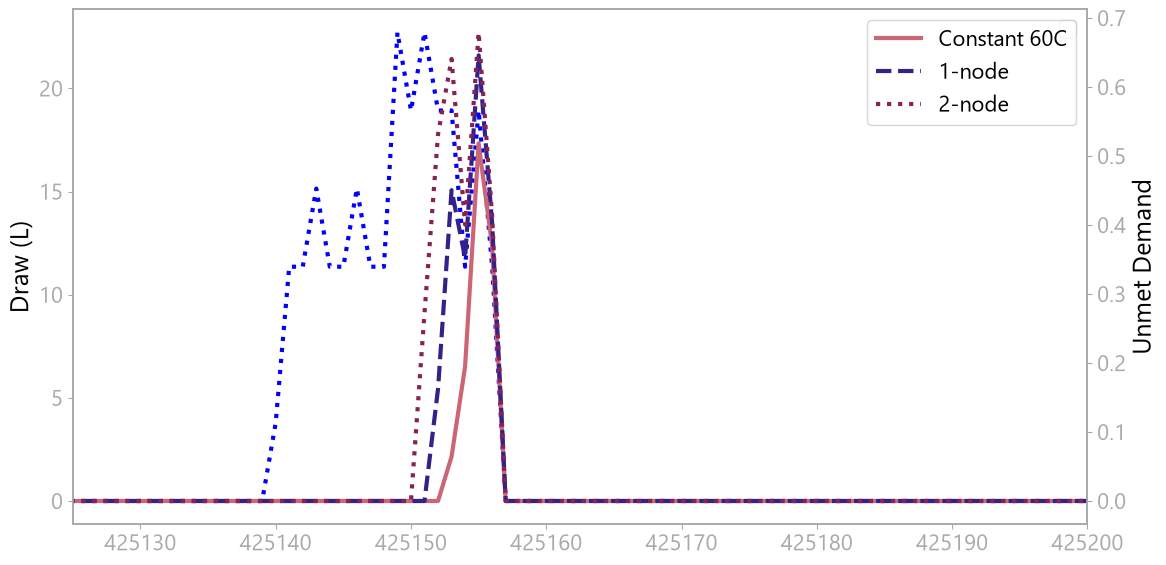

In [69]:
#Why isn't it working
site = 90159


mpc_1_rolling = pd.read_csv(f"output_site_{site}_bisection_rolling_1_120V.csv")
mpc_2_rolling = pd.read_csv(f"output_site_{site}_bisection_rolling_2_120V.csv")
constant_49 = pd.read_csv(f"output_site_{site}_151(L)_49_120V.csv") 
constant_60 = pd.read_csv(f"output_site_{site}_151(L)_60_120V.csv") 

#plt.plot(mpc_1_rolling["Draw Data"], label="Draw", linestyle = 'dotted', color="blue")
fig, ax = plt.subplots(figsize=(12, 6))

ax2 = ax.twinx()  # Create a secondary y-axis
#ax.plot(constant_49['Hot Water Unmet Demand (kWh)'], label="Constant 49C")
ax2.plot(constant_60['Hot Water Unmet Demand (kWh)'], label="Constant 60C")
ax2.plot(mpc_1_rolling['Hot Water Unmet Demand (kWh)'], label="1-node", linestyle = 'dashed')
ax2.plot(mpc_2_rolling['Hot Water Unmet Demand (kWh)'], label="2-node", linestyle = 'dotted')




#ax.plot(constant_49['Water Heating Electric Power (kWh)'], label="Constant 49C Energy")
#ax.plot(constant_60['Water Heating Electric Power (kWh)'], label="Constant 60C Energy")
#ax.plot(mpc_1_rolling['Water Heating Electric Power (kWh)'], label="1-node Energy", linestyle = 'dashed')
#ax.plot(mpc_2_rolling['Water Heating Electric Power (kWh)'], label="2-node Energy", linestyle = 'dotted')

ax.legend()

#ax2.plot(mpc_1_rolling['Setpoints'], label="1-node Setpoint", linestyle = 'dashed')
#ax2.plot(mpc_2_rolling['Setpoints'], label="2-node Setpoint", linestyle = 'dotted')

ax.plot(mpc_1_rolling["Draw Data"], label="Draw", linestyle = 'dotted', color="blue")
ax.set_ylabel("Draw (L)")
ax2.set_ylabel("Unmet Demand")

ax2.legend()

plt.xlim(425125, 425200)

In [355]:
data = pd.read_csv('output_site_13438_49_120V.csv')

data['Draw Data'].sum() /213


np.float64(265.79620638497653)

In [2]:
unmet_daily_draws.sort_values(by='avg_draw_L')

AttributeError: 'list' object has no attribute 'sort_values'

In [20]:
df_unmet_daily.sort_values(by= 'avg_draw_L')

,49_120V,avg_draw_L,gallon_size,49_240V,60_120V,60_240V,perfect_120V_12,rolling_120V_2,perfect_120V_2,rolling_240V_2,perfect_240V_2,rolling_120V_1,perfect_120V_1,rolling_240V_1,perfect_240V_1,load_shift_rolling_120V_2,load_shift_rolling_240V_2
0,0.002269,45.902876,60,0.002172,0.000000,0.000000,0.000000,0.001755,0.000000,0.002464,0.000805,0.000000,0.000000,0.000031,0.000000,0.000000,0.000000
9,0.000000,91.396950,80,0.000000,0.000000,0.000000,0.000000,0.000984,0.000000,0.001243,0.000652,0.000000,0.000000,0.000000,0.000000,0.002244,0.001922
1,0.009538,99.650438,60,0.009762,0.000012,0.000010,0.000138,0.008306,0.000000,0.010388,0.009303,0.000810,0.000123,0.000429,0.000233,0.018066,0.016519
2,0.004726,100.525811,60,0.004155,0.000000,0.000000,0.000000,0.002215,0.000000,0.003566,0.002554,0.000877,0.000000,0.001335,0.000571,0.000000,0.000000
4,0.047834,131.204180,60,0.046718,0.035752,0.034660,0.032739,0.050620,0.032916,0.049943,0.051552,0.039708,0.034350,0.039289,0.035251,0.035945,0.035188
3,0.047834,131.204180,60,0.046718,0.035752,0.034660,0.032739,0.050620,0.032916,0.049943,0.051552,0.039708,0.034350,0.039289,0.035251,0.035945,0.035188
5,0.040055,174.931066,60,0.033286,0.000049,0.000006,0.000052,0.025130,0.000570,0.027876,0.022895,0.004224,0.000039,0.005084,0.001771,0.011869,0.010589
6,0.014493,245.343692,60,0.013967,0.004242,0.004007,0.005372,0.015263,0.005356,0.017365,0.014787,0.005921,0.004089,0.005053,0.004143,0.005973,0.005740
7,0.051448,264.554168,60,0.044504,0.002443,0.002049,0.001932,0.039697,0.002829,0.035255,0.034194,0.013272,0.002636,0.012987,0.011350,0.031898,0.028580
8,0.034740,288.697918,60,0.026873,0.000085,0.000038,0.000000,0.041555,0.001144,0.040339,0.039320,0.004125,0.000000,0.004958,0.004264,0.043626,0.036146


#Generate Analysis on sites

In [4]:
#Creates x and y series that hold unmet and energy baseline comparisons (to 49C and 60C baseline respectively) for every site
#We can use these for generating figures to show efficacy of each method
x120, x240 = compare_unmet_baseline(df_unmet_daily)
y120, y240 = compare_energy_baseline(df_kWh_daily)



In [5]:
series = y120
#y240.sort_values(by="avg_draw_L")
#print(series.min())
#print(series.mean())
#print(series.max())

import numpy as np

# Apply min, mean, and max across columns
stats = x120.agg(['min', 'mean', 'max'])

# Print values rounded to 3 significant figures
formatted_stats = stats.map(lambda x: f"{x:.3g}" if pd.notnull(x) else x)
print(formatted_stats)

     gallon_size avg_draw_L 49_120V 60_120V rolling_120V_2 perfect_120V_2  \
min           50       45.9       0       0      -0.000985        -0.0244   
mean        64.8        184  0.0783       0         0.0643       -0.00292   
max           80        439   0.634       0          0.587        0.00111   

     rolling_120V_1 perfect_120V_1 load_shift_rolling_120V_2  
min       -0.000985        -0.0209                         0  
mean         0.0272       -0.00281                    0.0286  
max           0.264       0.000421                     0.445  


In [3]:

plt.scatter(x120['rolling_120V_2'], x120['rolling_120V_2'], label="Rolling Average 2-node MPC ")
plt.scatter(x120['perfect_120V_2'], x120['perfect_120V_2'], label="Perfect Average 2-node MPC ")
plt.scatter(x120['rolling_120V_1'], x120['rolling_120V_1'], label="Rolling Average 1-node MPC ")
plt.scatter(x120['perfect_120V_1'], x120['perfect_120V_1'], label="Perfect Average 1-node MPC ")
plt.scatter(x120['load_shift_rolling_120V_2'], x120['load_shift_rolling_120V_2'], label="Load Shift")
plt.ylabel("Daily Unmet Demand Deficit (kWh/Day)")
plt.xlabel("Daily Draw (L/Day)")
plt.legend()

NameError: name 'x120' is not defined

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def get_pareto_frontier(x, y, maximize_x=True, minimize_y=True):
    """
    Extracts the non-dominated Pareto optimal points from 2D data.
    """
    data = np.column_stack((x, y))
    data = data[~np.isnan(data).any(axis=1)]  # Drop NaNs
    
    # Sort primarily by X (descending if maximize_x), secondarily by Y
    x_dir = -1 if maximize_x else 1
    y_dir = 1 if minimize_y else -1
    sorted_idx = np.lexsort((y_dir * data[:, 1], x_dir * data[:, 0]))
    sorted_data = data[sorted_idx]
    
    pareto_front = []
    best_y = np.inf if minimize_y else -np.inf
    
    for px, py in sorted_data:
        if minimize_y and py < best_y:
            pareto_front.append((px, py))
            best_y = py
        elif not minimize_y and py > best_y:
            pareto_front.append((px, py))
            best_y = py
            
    pareto_front = np.array(pareto_front)
    if len(pareto_front) == 0:
        return np.empty((0, 2))
    
    # Sort by X ascending for clean line plotting
    return pareto_front[np.argsort(pareto_front[:, 0])]


# List of (column_name, label_name) tuples
datasets = [
    ('49_120V', 'Constant Setpoint (49 C)'),
    ('rolling_120V_2', "Rolling Average 2-node MPC"),
    #('perfect_120V_2', "Perfect Average 2-node MPC"),
    ('rolling_120V_1', "Rolling Average 1-node MPC"),
    #('perfect_120V_1', "Perfect Average 1-node MPC"),
    ('load_shift_rolling_120V_2', "Load Shift"),

]

plt.figure(figsize=(10, 6))

for col, label in datasets:
    y = x120[col] #Unmet Demand Comparison
    #x = y120[col] #Energy Baseline Comparison
    x = x120['avg_draw_L']
    
    # Plot scatter points
    #scatter = plt.scatter(x, y, label=label, alpha=0.6)
    #color = scatter.get_facecolor()[0]  # Match Pareto line color to scatter color
    
    # Compute Pareto frontier (Maximize X = Draw, Minimize Y = Deficit)
    pareto = get_pareto_frontier(x, y, maximize_x=True, minimize_y=True)
    
    #Plot connected Pareto frontier line
    if len(pareto) > 0:
        plt.plot(pareto[:, 0], pareto[:, 1], linestyle='--', linewidth=2, label=label) #color=color,

    #plot some horizontal line that indicates 60 performance

plt.title("120V Pareto Frontier")
plt.ylabel("Daily Unmet Demand Upper Bound (kWh/Day)")
plt.xlabel('Daily Water Draw (L/Day)')
#plt.xlabel("Daily Energy Usage (kWh/Day)")
plt.legend()
plt.tight_layout()
plt.xlim(150, 450)
plt.show()


NameError: name 'x120' is not defined

<Figure size 1000x600 with 0 Axes>

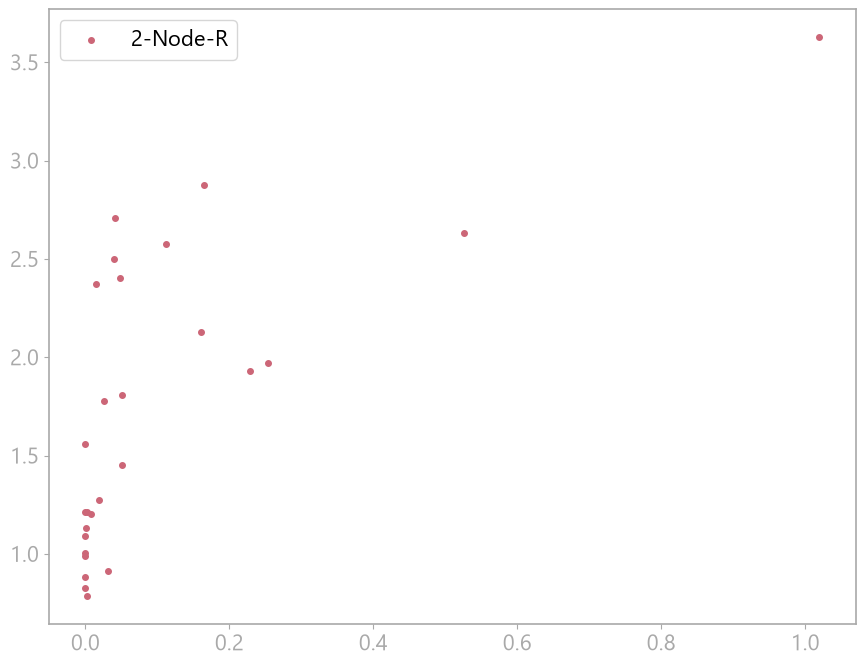

In [12]:

plt.scatter(df_unmet_daily['rolling_120V_2'], df_kWh_daily['rolling_120V_2'], label = "2-Node-R")
plt.legend()

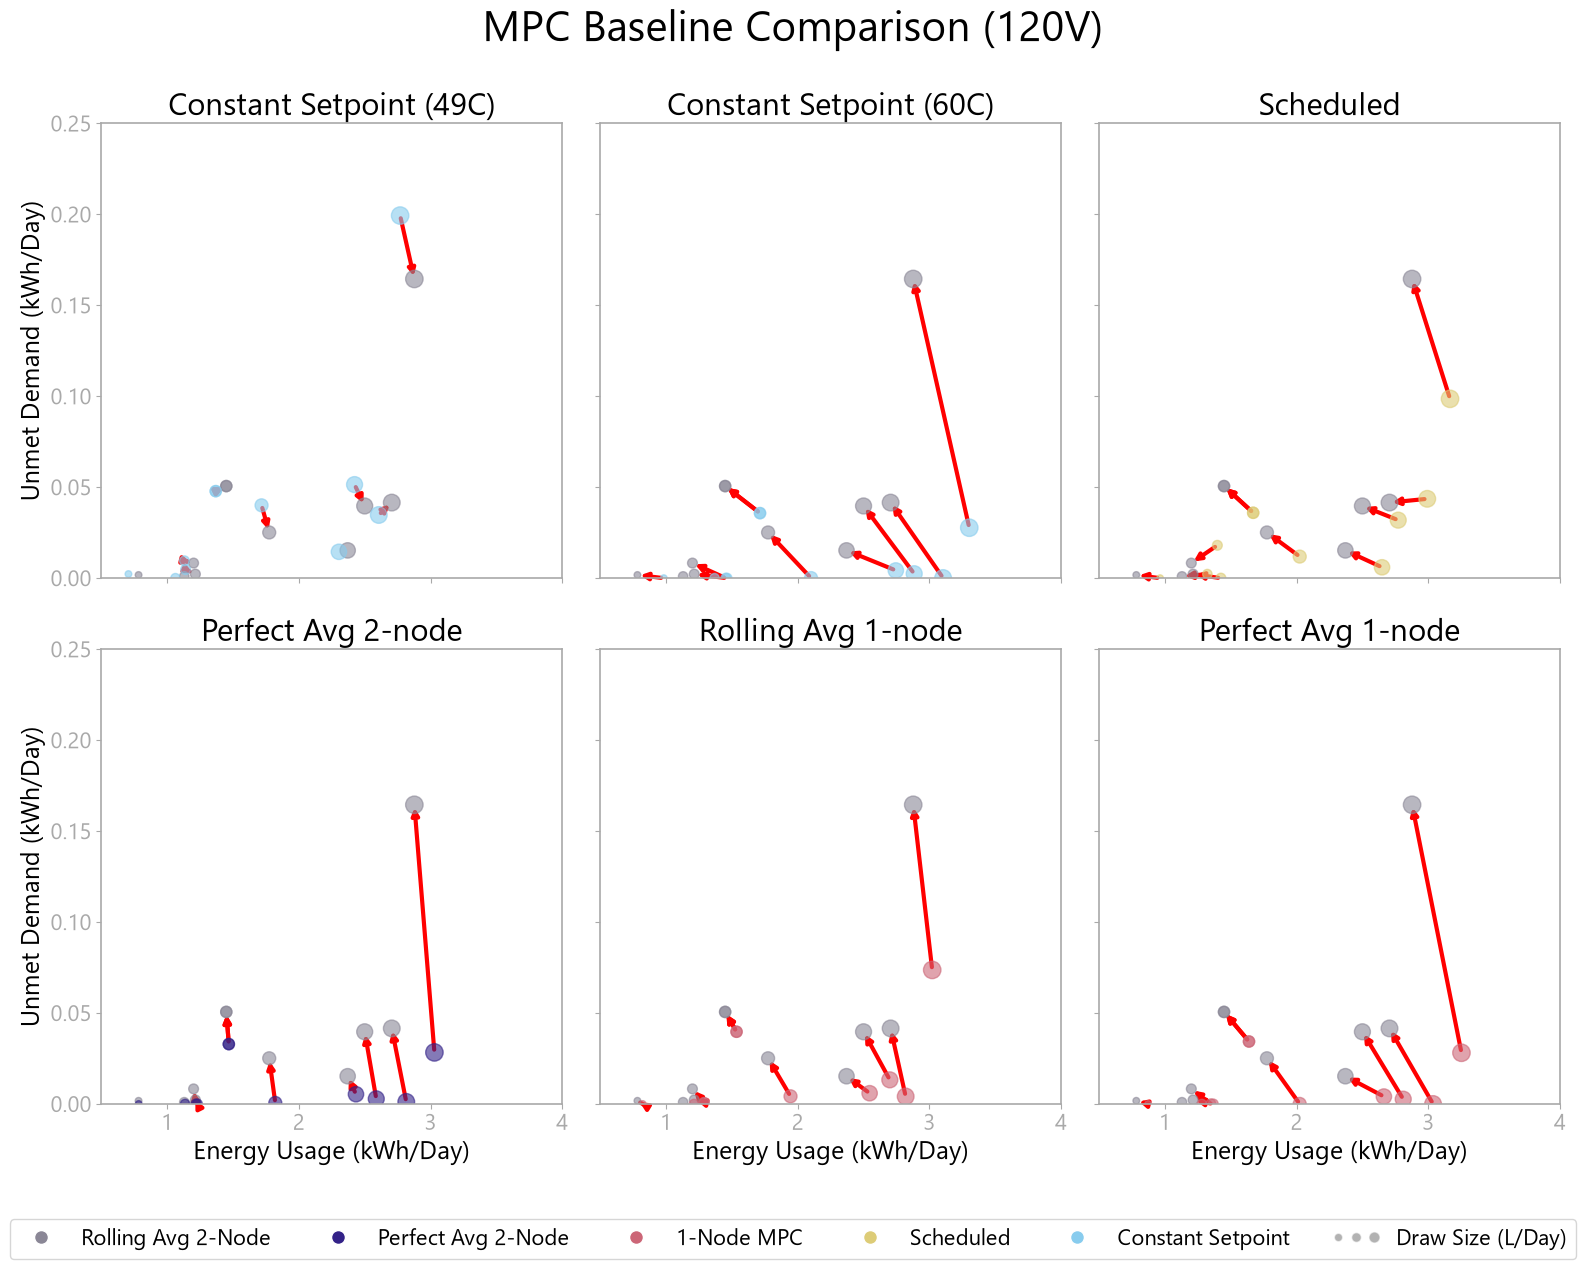

In [19]:
import numpy as np
import matplotlib.pyplot as plt
# --- ADD THIS IMPORT AT THE TOP OF YOUR SCRIPT ---
from matplotlib.collections import LineCollection


# 1. Datasets grouped by section: 2-Node first, then 1-Node

capacity = 120
ref_col = f'rolling_{capacity}V_2'
ref_label = "Rolling Avg 2-node"

# ref_col_2 = f'60_{capacity}V'
# ref_label = "Constant Setpoint (60C)"

datasets = [     
    #240 V
    ('49_240V', "Constant Setpoint (49C)"),
    ('60_240V', "Constant Setpoint (60C)"),
    ('load_shift_rolling_240V_2', "Scheduled"),
    #('rolling_240V_2', "Rolling Avg 2-node (240V)"),
    ('perfect_240V_2', "Perfect Avg 2-node"),
    ('rolling_240V_1', "Rolling Avg 1-node"),

    ('perfect_240V_1', "Perfect Avg 1-node"),]

if capacity == 120:
    datasets = [
        # --- 2-NODE SECTION ---
        ('49_120V', "Constant Setpoint (49C)"),
        ('60_120V', "Constant Setpoint (60C)"),

        ('load_shift_rolling_120V_2', "Scheduled"),

        #('rolling_120V_2', "Rolling Avg 2-node"),
        ('perfect_120V_2', "Perfect Avg 2-node"),

        ('rolling_120V_1', "Rolling Avg 1-node"),
        ('perfect_120V_1', "Perfect Avg 1-node"),

    ]

COLOR_PALETTE_MEASURE = ['#CC6677', '#332288', '#882255', '#88CCEE', '#AA4499', '#DDCC77']
COLOR_PALETTE_SIM = ['#44AA99', '#999933', '#AA4499', '#DDCC77']

COLOR_MAP = {
    'reference': "#8A8796",
    '2_node': '#332288',     # Purple/Blue for 2-node MPCs
    '1_node': '#CC6677',     # Rose/Red for 1-node MPCs
    'load_shift': '#DDCC77',  # Yellow/Gold for Load Shift
    'constant' : '#88CCEE' #Constant setpoint
}

# 2. Create a 3x3 subplot grid
fig, axes = plt.subplots(2, 3, figsize=(16, 13), sharex=True, sharey=True)
axes_flat = axes.flatten()


for idx, (col, label) in enumerate(datasets):

    
    ax = axes_flat[idx]

    # Data selector (120V vs 240V)


    x, y = df_kWh_daily[col], df_unmet_daily[col]
    dot_size = df_unmet_daily['avg_draw_L'] * 0.5


    # Color mapping
    if 'load_shift' in col:
        color = COLOR_MAP['load_shift']
    elif 'V_2' in col:
        color = COLOR_MAP['2_node']
    elif 'V_1' in col:
        color = COLOR_MAP['1_node']
    else:
        color = COLOR_MAP['constant']

    ref_x = df_kWh_daily[ref_col]
    ref_y = df_unmet_daily[ref_col]

    ref_points = np.column_stack([ref_x, ref_y])
    data_points = np.column_stack([x, y])
    segments = np.stack([ref_points, data_points], axis=1)

    # Add arrows pointing FROM the colored markers TO the gray reference markers
    arrow_props = dict(
        arrowstyle="-|>",        # Arrowhead style
        color="red",            # Arrow & line color
        linewidth=3,          # Line thickness
        alpha=1,              # Transparency
        mutation_scale=10       # Size of the arrowhead
    )

    for rx, ry, cx, cy in zip(ref_x, ref_y, x, y):
        if (abs(rx - cx) > 0.001) and (abs(ry - cy) > 0.001):
            ax.annotate(
                "",                            # No text label
                xy=(rx, ry),                   # Arrow tip points HERE (gray reference marker)
                xytext=(cx, cy),               # Arrow starts HERE (colored marker)
                arrowprops=arrow_props,
                zorder=1                       # Draw arrows underneath scatter dots
            )

    # 2. Add connecting lines behind markers using LineCollection
    # lc = LineCollection(
    #     segments,
    #     linewidths=1.5,      # Adjust thickness as needed

    #     alpha=1,          # Line transparency
    #     zorder=1             # Ensures lines draw behind the markers
    # )
    # ax.add_collection(lc)


     #Scatter mpc 2_node for reference
     
    ax.scatter(df_kWh_daily[ref_col], df_unmet_daily[ref_col], s = dot_size, color = COLOR_MAP['reference'], alpha = 0.6)
    #ax.scatter(df_kWh_daily[ref_col_2], df_unmet_daily[ref_col_2], s = dot_size, color = COLOR_MAP['1_node'], alpha = 0.6)
    
    
    # Scatter plot on the specific subplot
    ax.scatter(x, y, s=dot_size, color=color, alpha=0.6)

   
    # Reference bounds
    #ax.axhline(y=0, color='black', linestyle='dotted', alpha=0.6) #49
    #ax.axvline(x=0, color='#44AA99', linestyle='dotted', alpha=0.6) #60

    ax.set_title(label )


# 3. Label shared axes on outer subplots
for ax in axes[-1, :]:
    ax.set_xlabel("Energy Usage (kWh/Day)")

for ax in axes[:, 0]:
    ax.set_ylabel("Unmet Demand (kWh/Day)")

# 4. Global Figure Legend & Title
fig.suptitle(f"MPC Baseline Comparison ({capacity}V)", fontsize=30, y = 0.95)

# 1. Define 3 separate markers with increasing sizes
draw_small = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', alpha=0.6, markersize=6)
draw_med   = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', alpha=0.6, markersize=7)
draw_large = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', alpha=0.6, markersize=8)

from matplotlib.legend_handler import HandlerTuple
# 2. Build handles list (grouping the 3 dots in a tuple)
handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_MAP['reference'], markersize=10),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_MAP['2_node'], markersize=10),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_MAP['1_node'], markersize=10),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_MAP['load_shift'], markersize=10),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_MAP['constant'], markersize=10),
    (draw_small, draw_med, draw_large),  # Grouped tuple for the size scale
    #plt.Line2D([0], [0], color='black', linestyle='dotted'),
    #plt.Line2D([0], [0], color='#44AA99', linestyle='dotted')
]

labels = [
    'Rolling Avg 2-Node',
    'Perfect Avg 2-Node',
    '1-Node MPC',
    'Scheduled',
    'Constant Setpoint',
    'Draw Size (L/Day)',

]

# 3. Call fig.legend with handler_map
fig.legend(
    handles=handles,
    labels=labels,
    handler_map={(draw_small, draw_med, draw_large): HandlerTuple(ndivide=None)},
    loc='lower center',
    bbox_to_anchor=(0.5, -0.02),
    ncol=6,
    frameon=True
)


#plt.ylim(0, 1.2)
#plt.xlim(0, 5)

#plt.xlim(0, 5)
#plt.ylim(0, 1.2)
plt.xlim(0.5, 4)
plt.ylim(0, 0.25)
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()



In [7]:
df_unmet_daily

,49_120V,avg_draw_L,gallon_size,49_240V,60_120V,60_240V,rolling_120V_2,perfect_120V_2,rolling_240V_2,perfect_240V_2,rolling_120V_1,perfect_120V_1,rolling_240V_1,perfect_240V_1,load_shift_rolling_120V_2,load_shift_rolling_240V_2
0,0.004368,121.677884,50,0.003763,0.000532,0.000168,0.000000,0.000000,0.002649,0.002709,0.000000,0.000000,0.001400,0.000504,0.002282,0.002105
1,0.003903,132.018930,50,0.003067,0.000000,0.000000,0.000000,0.000000,0.001218,0.003027,0.000000,0.000036,0.000234,0.000032,0.001833,0.001952
2,0.000266,146.351031,50,0.000188,0.000000,0.000000,0.000000,0.000000,0.000551,0.000469,0.000000,0.000000,0.000000,0.000000,0.000299,0.000375
3,0.001218,172.722851,50,0.000859,0.000000,0.000000,0.000000,0.000000,0.000092,0.000073,0.000000,0.000000,0.000000,0.000000,0.001086,0.001017
4,0.040432,185.862060,50,0.032090,0.000985,0.000627,0.000000,0.000000,0.022405,0.022202,0.000000,0.000000,0.008485,0.003382,0.009554,0.007678
5,0.002269,45.902876,60,0.002172,0.000000,0.000000,0.000000,0.000000,0.002464,0.000805,0.000000,0.000000,0.000031,0.000000,0.000000,0.000000
6,0.049080,60.833138,60,0.048277,0.008875,0.009238,0.000000,0.000000,0.030454,0.027677,0.000000,0.000000,0.028563,0.021591,0.009223,0.005734
7,0.000000,74.052083,60,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
8,0.009538,99.650438,60,0.009762,0.000012,0.000010,0.010183,0.000000,0.010388,0.009303,0.000000,0.000000,0.000429,0.000233,0.018066,0.016519
9,0.004726,100.525811,60,0.004155,0.000000,0.000000,0.000000,0.000000,0.003566,0.002554,0.000000,0.000000,0.001335,0.000571,0.000000,0.000000


In [361]:
subset = [0, 3, 4, 9, 20, 21]
df_unmet_daily_rep = df_unmet_daily.iloc[subset]
df_kWh_daily_rep = df_kWh_daily.iloc[subset]

In [363]:
df_unmet_daily_rep

,49_120V,avg_draw_L,gallon_size,49_240V,60_120V,60_240V,rolling_120V_2,perfect_120V_2,rolling_240V_2,perfect_240V_2,rolling_120V_1,perfect_120V_1,rolling_240V_1,perfect_240V_1,load_shift_rolling_120V_2,load_shift_rolling_240V_2,draw_bin
0,0.004368,121.677884,50,0.003763,0.000532,0.000168,0.002977,0.002235,0.002649,0.002709,0.001307,0.000955,0.001400,0.000504,0.003310,0.004393,"(0, 170]"
3,0.001218,172.722851,50,0.000859,0.000000,0.000000,0.000178,0.000100,0.000092,0.000073,0.000000,0.000000,0.000000,0.000000,0.000002,0.000046,"(170, 500]"
4,0.040432,185.862060,50,0.032090,0.000985,0.000627,0.028724,0.024257,0.022405,0.022202,0.010206,0.004585,0.008485,0.003382,0.034704,0.031414,"(170, 500]"
9,0.004726,100.525811,60,0.004155,0.000000,0.000000,0.003089,0.002234,0.003566,0.002554,0.001940,0.000811,0.001335,0.000571,0.003194,0.002189,"(0, 170]"
20,0.276053,205.320638,80,0.255637,0.089378,0.077781,0.263905,0.251104,0.250953,0.225876,0.162848,0.135391,0.152792,0.120790,0.251053,0.228977,"(170, 500]"
21,0.193899,219.843726,80,0.172699,0.059486,0.054940,0.175004,0.157621,0.162955,0.139836,0.102434,0.077525,0.094339,0.067686,0.152871,0.141166,"(170, 500]"


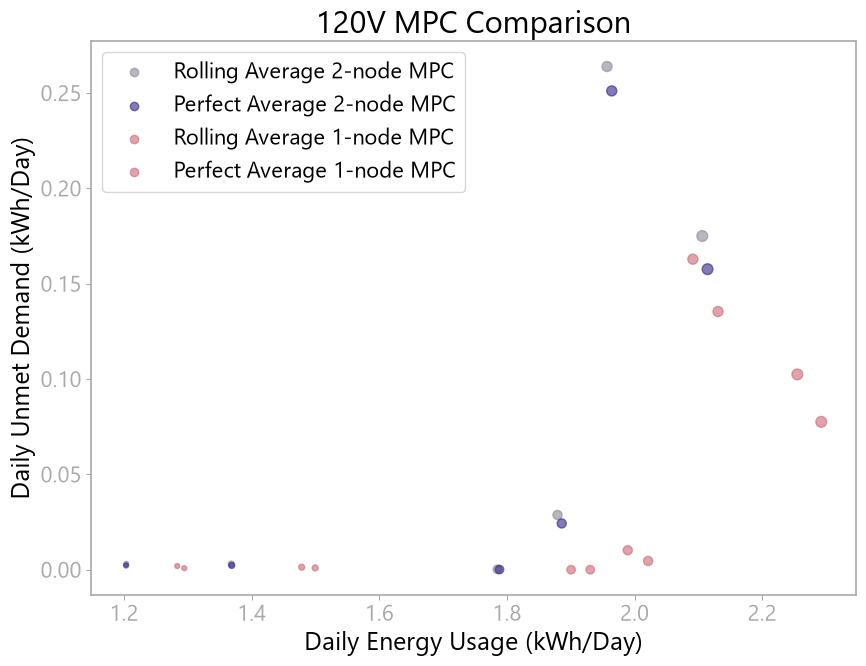

In [376]:
capacity = 120

datasets = [
    
    ('rolling_120V_2', "Rolling Average 2-node MPC"),
    #('49_120V', 'Constant Setpoint (49 C)'),
    #('60_120V', 'Constant Setpoint (60 C)'),
    ('perfect_120V_2', "Perfect Average 2-node MPC"),
    ('rolling_120V_1', "Rolling Average 1-node MPC"),
    ('perfect_120V_1', "Perfect Average 1-node MPC"),
    #'load_shift_rolling_120V_2', "Schedule"),

]

if capacity == 240:
    datasets = [
        
        ('rolling_240V_2', "Rolling Average 2-node MPC"),
        ('49_240V', 'Constant Setpoint (49 C)'),
        ('60_240V', 'Constant Setpoint (60 C)'),
        #('perfect_240V_2', "Perfect Average 2-node MPC"),
        #('rolling_240V_1', "Rolling Average 1-node MPC"),
        #('perfect_240V_1', "Perfect Average 1-node MPC"),
        ('load_shift_rolling_240V_2', "Schedule"),

    ]


# Graph for 240 V results


COLOR_MAP = {
    'reference': "#8A8796",
    '2_node': '#332288',     # Purple/Blue for 2-node MPCs
    '1_node': '#CC6677',     # Rose/Red for 1-node MPCs
    'load_shift': '#DDCC77',  # Yellow/Gold for Load Shift
    'constant' : '#88CCEE' #Constant setpoint
}

for col, label in datasets:
    y = df_unmet_daily_rep[col] #Unmet Demand Comparison
    x = df_kWh_daily_rep[col] #Energy Baseline Comparison
    
    dot_size = ((df_unmet_daily_rep['avg_draw_L'])**2 /800 ) #Dot size proportional to gallon size
    # Plot scatter points
    if label == "Rolling Average 2-node MPC":
        scatter = plt.scatter(x, y, s = dot_size, label=label, alpha=0.6, color=COLOR_MAP['reference'])
    elif label == "Schedule":
        scatter = plt.scatter(x, y, s = dot_size, label=label, alpha=0.6, color = COLOR_MAP['load_shift'])
    elif label == "Perfect Average 2-node MPC":
            scatter = plt.scatter(x, y, s = dot_size, label=label, alpha=0.6, color = COLOR_MAP['2_node'])
    elif label == "Rolling Average 1-node MPC":
        scatter = plt.scatter(x, y, s = dot_size, label=label, alpha=0.6, color = COLOR_MAP['1_node'])
        
    else:
        scatter = plt.scatter(x, y, s = dot_size, label=label, alpha=0.6)



#plt.scatter([], [], s=50, c='gray', alpha=0.6, label=f'Draw Data (L/Day)')
#plt.axhline(y = 0,  label = "60 C Lower Bound", linestyle = "dotted")            
#plt.axvline(x = 0, color='#44AA99', label = "49 C Lower Bound", linestyle = 'dotted')            

plt.title(f"{capacity}V MPC Comparison")
plt.ylabel("Daily Unmet Demand (kWh/Day)")    
plt.xlabel("Daily Energy Usage (kWh/Day)")
plt.legend()
plt.tight_layout()
plt.show()

In [283]:
df_kWh_daily

,49_120V,avg_draw_L,gallon_size,49_240V,60_120V,60_240V,rolling_120V_2,perfect_120V_2,rolling_240V_2,perfect_240V_2,rolling_120V_1,perfect_120V_1,rolling_240V_1,perfect_240V_1,load_shift_rolling_120V_2,load_shift_rolling_240V_2
0,1.311495,121.677884,50,1.070797,1.645205,1.371393,1.367908,1.368624,1.121084,1.122245,1.478317,1.499402,1.217135,1.236032,1.485826,1.239858
1,1.383532,132.018930,50,1.130133,1.727651,1.440808,1.441775,1.443599,1.182403,1.182328,1.544079,1.565940,1.272521,1.290639,1.563885,1.304388
2,1.507583,146.351031,50,1.229707,1.857281,1.544387,1.569149,1.570053,1.285708,1.286687,1.679252,1.704238,1.382386,1.403174,1.668550,1.386480
3,1.718430,172.722851,50,1.401345,2.095873,1.741718,1.784954,1.788257,1.461795,1.465940,1.900484,1.930462,1.563369,1.588652,1.902518,1.578893
4,1.801233,185.862060,50,1.470601,2.201134,1.828035,1.879160,1.885793,1.539206,1.544137,1.989235,2.021204,1.634628,1.663295,2.008163,1.663992
5,0.706391,45.902876,60,0.581132,0.983543,0.834527,0.775802,0.777132,0.643952,0.644099,0.820838,0.825215,0.683619,0.687230,0.917260,0.778560
6,0.810649,60.833138,60,0.666883,1.109622,0.939751,0.902775,0.904897,0.749737,0.751211,0.921029,0.932580,0.765265,0.774801,1.028639,0.870363
7,0.936862,74.052083,60,0.767202,1.233086,1.035563,0.996125,0.995772,0.819495,0.820101,1.089026,1.092026,0.901812,0.904729,1.121192,0.941600
8,1.131516,99.650438,60,0.925726,1.454354,1.218541,1.188784,1.188781,0.976525,0.976744,1.287161,1.298215,1.064383,1.073719,1.346515,1.129685
9,1.140386,100.525811,60,0.932949,1.463435,1.226490,1.203433,1.203038,0.988896,0.989037,1.283269,1.294237,1.061602,1.069860,1.338153,1.121176


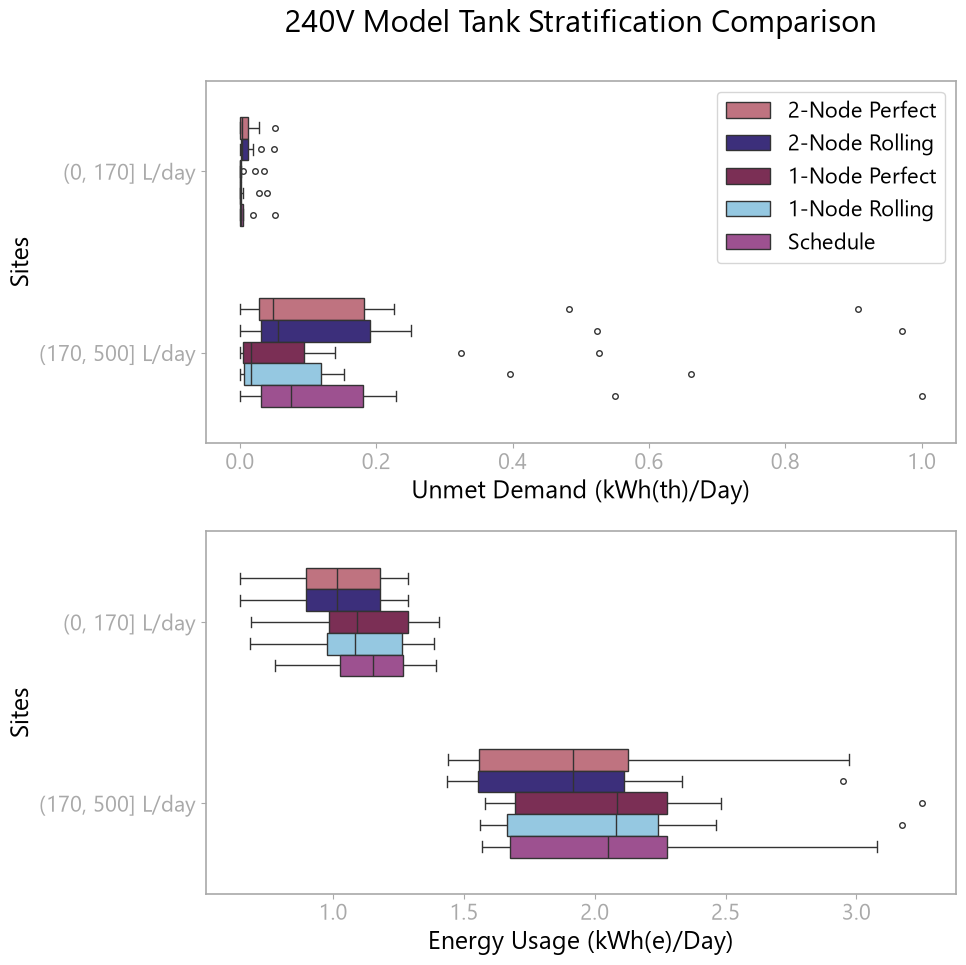

In [347]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

power_capacity = 240

# 1. Define column mappings and friendly display names
strategies = {
    'perfect_120V_2': '2-Node Perfect',
    'rolling_120V_2': '2-Node Rolling',
    'perfect_120V_1': '1-Node Perfect',
    'rolling_120V_1': '1-Node Rolling',
    'load_shift_rolling_120V_2': 'Schedule',  
}

if power_capacity == 240:
    strategies = {      
        'perfect_240V_2': '2-Node Perfect',
        'rolling_240V_2': '2-Node Rolling',
        'perfect_240V_1': '1-Node Perfect',
        'rolling_240V_1': '1-Node Rolling',
        'load_shift_rolling_240V_2': 'Schedule'
    }

# 2. Define features to process
features = [
    ('Unmet Demand', df_unmet_daily),
    ('Energy Baseline', df_kWh_daily),
]

# Set draw bin
df_unmet_daily['draw_bin'] = pd.cut(df_unmet_daily['avg_draw_L'], bins=[0, 170, 500])

# 3. Reshape datasets
melted_list = []
for feature_name, data_df in features:
    temp_dict = {'draw_bin': df_unmet_daily['draw_bin']}
    for col_key, display_label in strategies.items():
        temp_dict[display_label] = data_df[col_key]

    temp_df = pd.DataFrame(temp_dict)

    melted = temp_df.melt(
        id_vars=['draw_bin'],
        value_vars=list(strategies.values()),
        var_name='Strategy',
        value_name='kWh_per_Day',
    )
    melted['Feature'] = feature_name
    melted_list.append(melted)

combined_df = pd.concat(melted_list, ignore_index=True)

# Format y-axis category labels
combined_df['Draw_Label'] = combined_df['draw_bin'].astype(str) + " L/day"

# 4. Create 2 stacked subplots sharing the same figure
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(10, 10), sharey=True)

# --- Top Subplot: Unmet Demand (kWh_th on top axis) ---
unmet_data = combined_df[combined_df['Feature'] == 'Unmet Demand']
sns.boxplot(
    data=unmet_data,
    y='Draw_Label',
    x='kWh_per_Day',
    hue='Strategy',
    width=0.6,
    ax=ax_top
)

ax_top.set_title(f'{power_capacity}V Model Tank Stratification Comparison', pad=35)
ax_top.set_ylabel('Sites')
ax_top.set_xlabel('')  # Hide standard bottom x-label for top plot
ax_top.xaxis.tick_bottom()  # Move primary ticks to top
ax_top.xaxis.set_label_position('bottom')

ax_top.set_xlabel('Unmet Demand (kWh(th)/Day)')

# --- Bottom Subplot: Energy Baseline (kWhe on bottom axis) ---
baseline_data = combined_df[combined_df['Feature'] == 'Energy Baseline']
sns.boxplot(
    data=baseline_data,
    y='Draw_Label',
    x='kWh_per_Day',
    hue='Strategy',
    width=0.6,
    ax=ax_bottom
)


ax_bottom.set_ylabel('Sites')
ax_bottom.set_xlabel('Energy Usage (kWh(e)/Day)')

# Clean up redundant legends
ax_top.legend(loc='upper right')
ax_bottom.legend().remove()  # Avoid duplicating legend on second plot

plt.tight_layout()
plt.show()

In [325]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns




for col, label in datasets:
    # 2. Build a temporary DataFrame for the current column
    temp_df = pd.DataFrame({
        'draw_bin': x120['draw_bin'],
        'Energy Usage': y120[col],
        'Unmet Demand': x120[col]
    })

    # 3. Reshape data into long format for Seaborn grouping
    melted_df = temp_df.melt(
        id_vars=['draw_bin'],
        value_vars=['Energy Usage', 'Unmet Demand'],
        var_name='Metric',
        value_name='kWh_per_Day'
    )

    # 4. Plot side-by-side boxes per bin
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=melted_df,
        x='draw_bin',
        y='kWh_per_Day',
        hue='Metric',

    )

    plt.title(f"120V Metrics by Draw Range: {label}")
    plt.xlabel("Draw Data (L/Day)")
    plt.ylabel("kWh / Day")
    plt.xticks(rotation=20)
    plt.legend(title="Metric", loc="upper left")
    plt.tight_layout()
    plt.show()

KeyError: 'draw_bin'

# 240 V Discussion

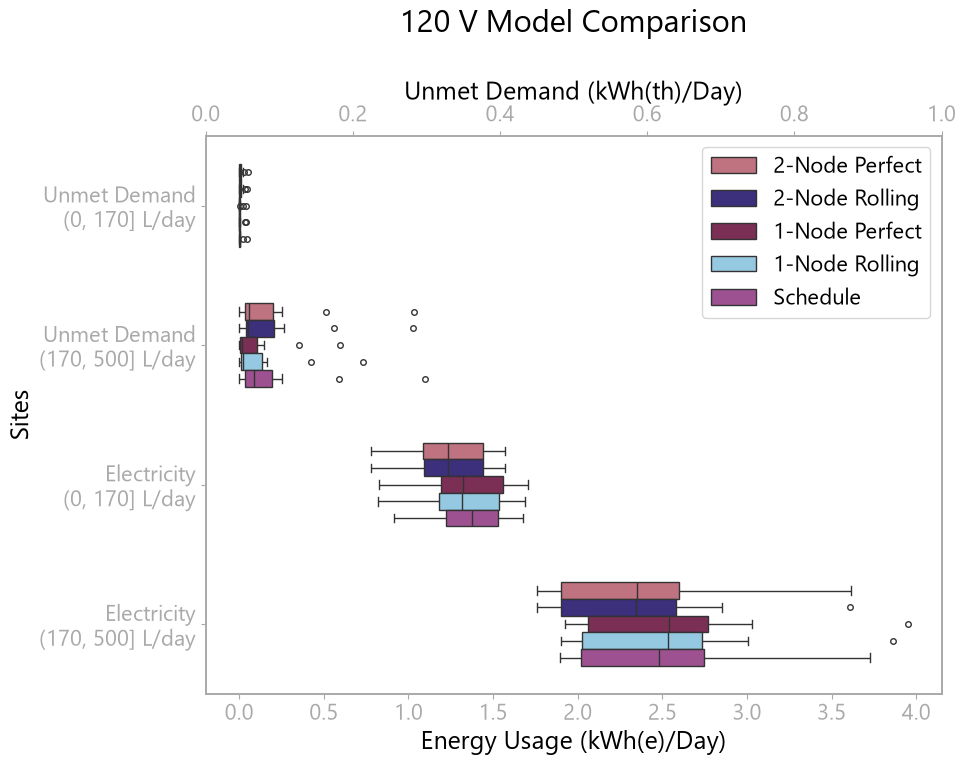

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

power_capacity = 120

# 1. Define column mappings and friendly display names
strategies = {
    'perfect_120V_2': '2-Node Perfect',
    'rolling_120V_2': '2-Node Rolling',
    'perfect_120V_1': '1-Node Perfect',
    'rolling_120V_1': '1-Node Rolling',
    'load_shift_rolling_120V_2': 'Schedule',  
}

if power_capacity == 240:
    strategies = {      
        'perfect_240V_2': '2-Node Perfect',
        'rolling_240V_2': '2-Node Rolling',
        'perfect_240V_1': '1-Node Perfect',
        'rolling_240V_1': '1-Node Rolling',
        'load_shift_rolling_240V_2': 'Schedule'
    }

# 2. Define features to process
features = [
    ('Unmet Demand', df_unmet_daily),
    ('Electricity', df_kWh_daily),
]

# Set draw bin
df_unmet_daily['draw_bin'] = pd.cut(df_unmet_daily['avg_draw_L'], bins=[0, 170, 500])

# 3. Reshape and concatenate both feature datasets into a single DataFrame
melted_list = []
for feature_name, data_df in features:
    temp_dict = {'draw_bin': df_unmet_daily['draw_bin']}
    for col_key, display_label in strategies.items():
        temp_dict[display_label] = data_df[col_key]

    temp_df = pd.DataFrame(temp_dict)

    melted = temp_df.melt(
        id_vars=['draw_bin'],
        value_vars=list(strategies.values()),
        var_name='Strategy',
        value_name='kWh_per_Day',
    )
    melted['Feature'] = feature_name
    melted_list.append(melted)

combined_df = pd.concat(melted_list, ignore_index=True)

# 4. Create combined vertical label (Method + Draw Value)
combined_df['Vertical_Group'] = (
    combined_df['Feature'] + '\n' + combined_df['draw_bin'].astype(str) +  " L/day"
)

# 5. Plot graph with primary (bottom) and secondary (top) x-axes
fig, ax1 = plt.subplots(figsize=(10, 8))

# Primary Axis Plotting (kWhe)
sns.boxplot(
    data=combined_df,
    y='Vertical_Group',
    x='kWh_per_Day',
    hue='Strategy',
    width=0.6,
    ax=ax1
)

ax1.set_title(f'{power_capacity} V Model Comparison', pad=35)  # Pad leaves room for top x-axis label
ax1.set_xlabel('Energy Usage (kWh(e)/Day)')
ax1.set_ylabel('Sites')
ax1.legend(loc='upper right')

# Create secondary twin x-axis on top (kWhth)
ax2 = ax1.twiny()

# Set upper x-axis limits synchronized with lower axis using conversion factor

ax2.set_xlabel('Unmet Demand (kWh(th)/Day)')

plt.tight_layout()
plt.show()

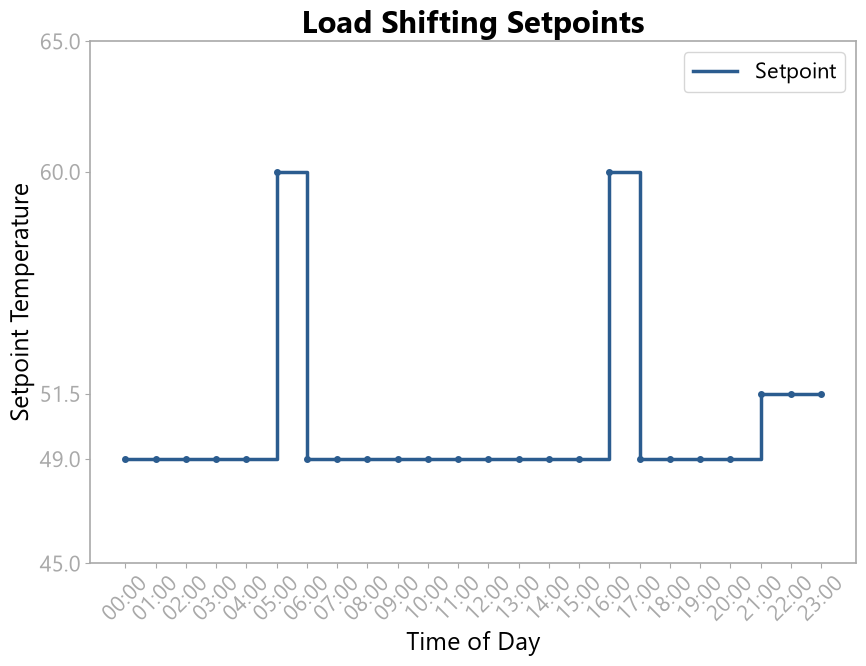

In [212]:
import matplotlib.pyplot as plt

# Generate hours from 0 to 23
hours = list(range(24))

# Compute setpoint based on hourly conditions
setpoints = []
for h in hours:
    if 0 <= h < 5:        # Lowest cost, minimal usage
        setpoints.append(49.0)
    elif 5 <= h < 6:      # Pre-heat ahead of rising morning cost
        setpoints.append(60.0)
    elif 6 <= h < 16:     # Work hours / setback
        setpoints.append(49.0)
    elif 16 <= h < 17:    # Pre-heat before evening peak
        setpoints.append(60.0)
    elif 17 <= h < 21:    # Peak usage window (5 PM - 9 PM)
        setpoints.append(49.0)
    else:                 # Late evening / overnight transition
        setpoints.append(51.5)

# Format time labels for x-axis
time_labels = [f"{h:02d}:00" for h in hours]

# Plotting

plt.step(hours, setpoints, where='post', color='#2b5c8f', linewidth=2.5, label='Setpoint')
plt.scatter(hours, setpoints, color='#2b5c8f', zorder=5)

plt.title('Load Shifting Setpoints', fontweight='bold')
plt.xlabel('Time of Day')
plt.ylabel('Setpoint Temperature')
plt.xticks(hours, time_labels, rotation=45)
plt.yticks([45, 49, 51.5, 60, 65])
plt.legend(loc='upper right')
plt.tight_layout()

plt.show()

In [156]:
constant_49[constant_49['Hot Water Unmet Demand (kWh)'] > 0]

,Hot Water Outlet Temperature (C),Hot Water Unmet Demand (kWh),Water Heating Electric Power (kWh),Water Heating Heat Pump COP (-),Water Heating Mode,Setpoints,Draw Data
15001,40.427587,0.000563,0.006998,7.173545,Heat Pump On,49,3.78541
15006,40.364344,0.000841,0.007063,7.080686,Heat Pump On,49,3.78541
15010,40.298353,0.001131,0.007102,7.025971,Heat Pump On,49,3.78541
15019,40.195472,0.001584,0.007263,6.802143,Heat Pump On,49,3.78541
15060,39.917898,0.002805,0.008073,5.717989,Heat Pump On,49,3.78541
...,...,...,...,...,...,...,...
278152,35.096719,0.024010,0.007652,6.270647,Heat Pump On,49,3.78541
278154,35.272725,0.023236,0.007607,6.330481,Heat Pump On,49,3.78541
278160,35.806527,0.020888,0.007643,6.281999,Heat Pump On,49,3.78541
278194,39.677093,0.003864,0.008142,5.630194,Heat Pump On,49,3.78541


78.86296913765935
78.86296913765935
0.3884875326978293
55.838962949492355
0.2750687830024254


In [187]:
constant_49['Hot Water Unmet Demand (kWh)'].sum()

np.float64(196.6368535662217)